# OISST over the North Pacific: 35 years of heatwaves and the 2012–2018 Blob

NOAA OISST over 25°N–55°N and 160°E–130°W (120 x 280 cells, 33,540 of them ocean, longitudes kept in 0–360 because the box crosses the dateline). Marine heatwaves and cold spells are detected for all of 1991–2025 with the fixed 1991–2020 climatology; objects, tracking and genealogy, with the per-cell catalog, are built for 2012–2018, the years of the 2013–2016 "Blob". Patches use an absolute 10,000 km² minimum, because the default 5% of this domain would discard 99% of them. Reproduced numbers are pending scientific review.

Read [the tutorial guide](../docs/TUTORIALS.md#north-pacific-oisst). Saved outputs can be read without data; re-execution needs the compressed OISST North Pacific dataset of [the README](../README.md) and memory for the global 2012–2018 spatial window. Full-period temporal detection runs in four-row latitude blocks, retaining every date per cell. No download is triggered by this notebook.

## Configuration of these saved outputs

| Choice | Value |
|---|---|
| Publication | 0.1.0 |
| Source | NOAA OISST v2.1 AVHRR-only, North Pacific (registered sha256 in report.json) |
| Reference period | 1991-01-01 through 2020-12-31 |
| Baseline / fit mode | fixed_climatology / retrospective |
| Seasonal pooling / smoothing (days) | 11 / 31 |
| Percentile estimator | hyndman_fan_7 |
| Minimum samples | 264 |
| Leap policy | hobday_366_interp |
| Within-reference correction | none |
| Representative tail / percentile / comparator | upper / 90.0 / > |
| Minimum duration / temporal gap (days) | 5 / 2 |
| Missing / join policy | as_non_exceedance / qualify_then_join |
| Declared day | native |
| Support / spatial dimensions | surface / lat, lon |
| Domain / measure | ocean / area |
| Review status | executed; summaries pending scientific review |

Detection over the whole period uses this baseline; the 2012–2018 window reuses it. A dynamic baseline is not run: its four time-by-cell float64 fields would need about 14 GB. Full portable specs and checksums are in `report.json` and [the saved run record](../docs/run_records/oisst_npacific.json).

In [1]:
import os
import sys
from pathlib import Path

EXAMPLES = Path.cwd() if (Path.cwd() / "_data.py").exists() else Path.cwd() / "examples"
sys.path.insert(0, str(EXAMPLES))
%matplotlib inline
data_dir = Path(os.environ.get("XHW_DATA_DIR", EXAMPLES.parent / "data"))
output_dir = Path(os.environ.get("XHW_OUTPUT_DIR", EXAMPLES.parent / "outputs")) / "npacific"

## Named configurations for the example

`mhw` and the other names below are local Python aliases containing complete
DefinitionSpec values, not extra arguments or automatic presets in `xhw.detect`.
Inspect them with `.to_dict()`. The loader still declares the baseline, reference
period and grid. The volume example keeps its potential-temperature definition.


In [2]:
from profiles import example_profiles

definitions = example_profiles()
mhw, mcs = definitions["mhw"], definitions["mcs"]
ahw_tx90, ahw_tn90 = definitions["ahw_tx90"], definitions["ahw_tn90"]
ahw_txtn90 = definitions["ahw_txtn90"]
ahw_tx_then_tn90 = definitions["ahw_tx_then_tn90"]
{name: (spec.phenomenon, spec.profile) for name, spec in definitions.items()}


{'mhw': ('mhw', 'hobday2016'),
 'mcs': ('mcs', 'schlegel2021'),
 'ahw_tx90': ('ahw', 'perkins2013_tx90'),
 'ahw_tn90': ('ahw', 'perkins2013_tn90'),
 'ahw_txtn90': ('ahw', 'xhw_txtn90'),
 'ahw_tx_then_tn90': ('ahw', 'xhw_tx_then_tn90')}

In [3]:
from _data import marine_definition
from _report import (
    frequency,
    lineage_catalog_status,
    mask_summary,
    spatial_summary,
    temporal_summary,
    write_report,
)
from oisst_npacific import SPATIAL, WINDOW, frequency_figure, load_oisst_npacific
from plotting import genealogy_figure, largest_event, metrics_figure, sequence_figure, series_figure

import xhw

print(f"Publication API: xHW {xhw.__version__}")

## Open the registered 1991-2025 subset (or its compressed copy) and declare its grid

Input is the registered North Pacific subset (or its compressed copy, checked by stored content). Interpolation of short gaps is explicit and fills nothing here.

In [4]:
raw, grid, baseline, definition = load_oisst_npacific(data_dir)
# Alias of the complete, case-specific definition.
mhw = definition
grid.check(raw)
ocean_cells = int(raw.domain_mask.sum())
print(f"OISST North Pacific; {ocean_cells} ocean cells; reference 1991–2020.", flush=True)


OISST North Pacific; 33540 ocean cells; reference 1991–2020.


## Marine heatwaves and cold spells over all 35 years; keep summaries, not the large masks

Each definition has its own threshold. Only the cell-day counts and the frequency map are kept from the full-period masks; a catalog of the roughly 2.7 million per-cell events would take hours in 0.1.0.

lat0000_0004: both full-period temporal masks checked


lat0004_0008: both full-period temporal masks checked


lat0008_0012: both full-period temporal masks checked


lat0012_0016: both full-period temporal masks checked


lat0016_0020: both full-period temporal masks checked


...

lat0100_0104: both full-period temporal masks checked


lat0104_0108: both full-period temporal masks checked


lat0108_0112: both full-period temporal masks checked


lat0112_0116: both full-period temporal masks checked


lat0116_0120: both full-period temporal masks checked


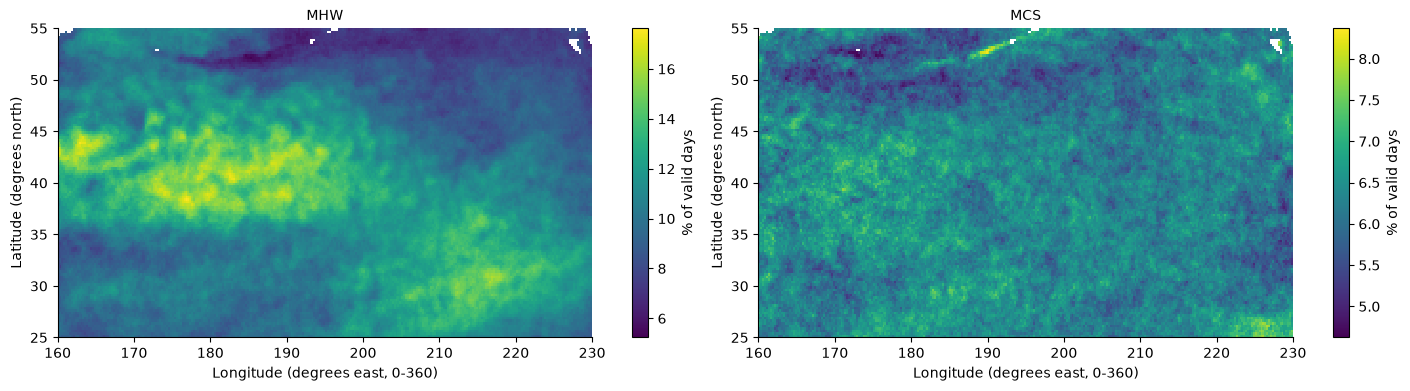

In [5]:
import xarray as xr
from _report import export_products
from npacific_blocks import BLOCK_ROWS, combine_baselines, latitude_blocks

rows = BLOCK_ROWS
products_dir = None  # the paired script exports the full-period block masks
detectors = {'MHW': definition, 'MCS': marine_definition(cold=True)}
metrics = {name: {} for name in detectors}
frequency_parts = {name: [] for name in detectors}
fit_parts = {name: [] for name in detectors}
windows, entries = [], {}
for label, tile in latitude_blocks(raw, rows=rows):
    prepared = xhw.interpolate_gaps(tile, variable='sst', grid=grid,
                                   max_days=2, max_filled_fraction=0.05)
    # Preserve full-period filled fractions and edge context in the saved window.
    windows.append(prepared.sel(time=slice(*WINDOW)).copy(deep=True))
    for name, detector in detectors.items():
        fitted = xhw.fit_baseline(prepared, variable='sst', grid=grid,
                                  baseline=baseline, definition=detector)
        fitted.check_invariants()
        mask = xhw.detect(prepared, variable='sst', grid=grid, definition=detector,
                          baseline_result=fitted)
        mask.check_invariants()
        for key, value in mask_summary(mask).items():
            metrics[name][key] = metrics[name].get(key, 0) + value
        frequency_parts[name].append(frequency(mask))
        fit_parts[name].append(fitted)
        if products_dir is not None:
            entries |= export_products(products_dir, f'{name.lower()}_1991_2025_{label}',
                                       mask=mask)
        del mask, fitted
    del prepared, tile
    print(f'{label}: both full-period temporal masks checked', flush=True)
raw.close()
prepared_window = xr.concat(windows, dim='lat', data_vars='minimal', coords='minimal',
                            compat='equals', combine_attrs='drop_conflicts')
del windows
fits, frequencies = {}, {}
for name, detector in detectors.items():
    fits[name] = combine_baselines(fit_parts.pop(name), grid, baseline, detector)
    frequencies[name] = xr.concat(frequency_parts[name], dim='lat')
    if products_dir is not None:
        entries |= export_products(products_dir, f'{name.lower()}_1991_2025',
                                   baseline=fits[name])
window = prepared_window
del raw, prepared_window
del fits["MCS"]
figure = frequency_figure(frequencies, output_dir)
del figure


## The Blob window: objects, explicit tracking and genealogy with the same baseline

The same fitted baseline is applied to 2012–2018, where the per-cell catalog, the objects, the explicit tracking and the lineage graph are built.

Catalog export constraint: 308 graph components are shorter than 5 days. Use graph.dataset for these components.


plotting.py:72: UserWarning: AutoDateLocator was unable to pick an appropriate interval for this date range. It may be necessary to add an interval value to the AutoDateLocator's intervald dictionary. Defaulting to 6.
  fig.savefig(output_dir / f"{name}.png", dpi=150, bbox_inches="tight")


events.py:101: UserWarning: AutoDateLocator was unable to pick an appropriate interval for this date range. It may be necessary to add an interval value to the AutoDateLocator's intervald dictionary. Defaulting to 6.
  func(*args, **kwargs)


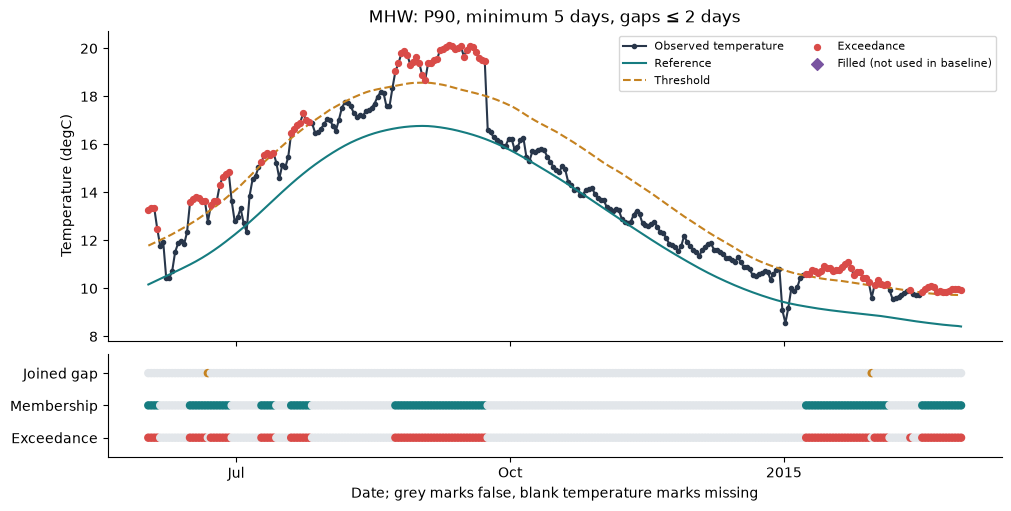

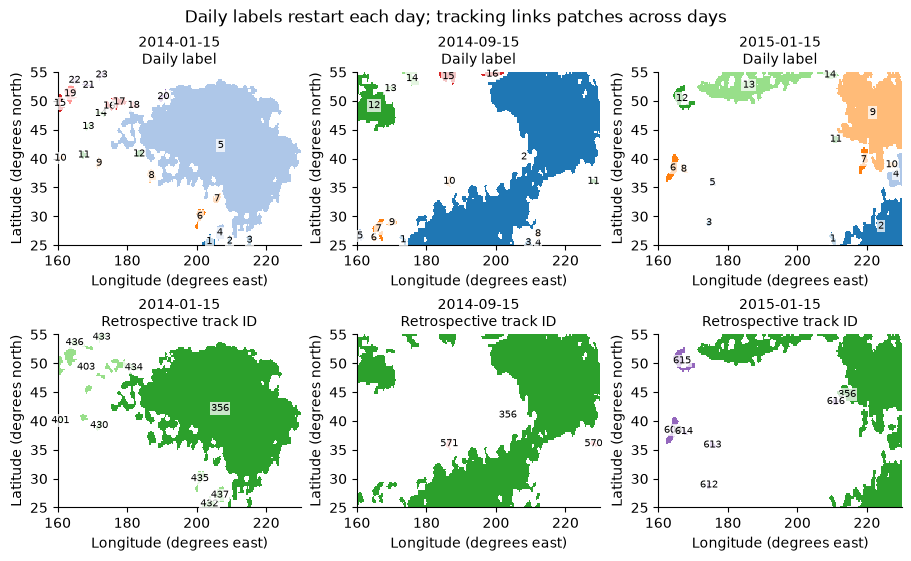

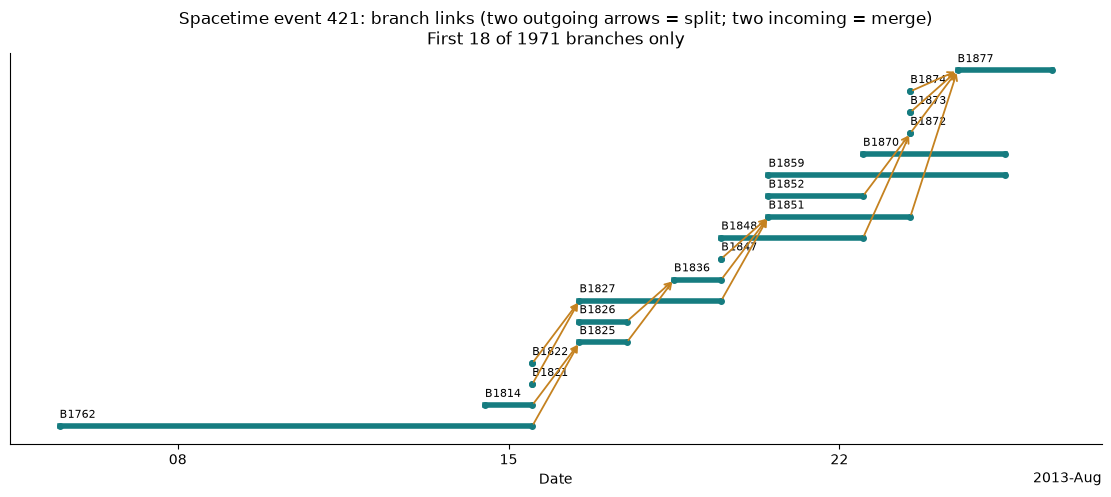

pylabtools.py:158: UserWarning: AutoDateLocator was unable to pick an appropriate interval for this date range. It may be necessary to add an interval value to the AutoDateLocator's intervald dictionary. Defaulting to 6.
  fig.canvas.print_figure(bytes_io, **kw)


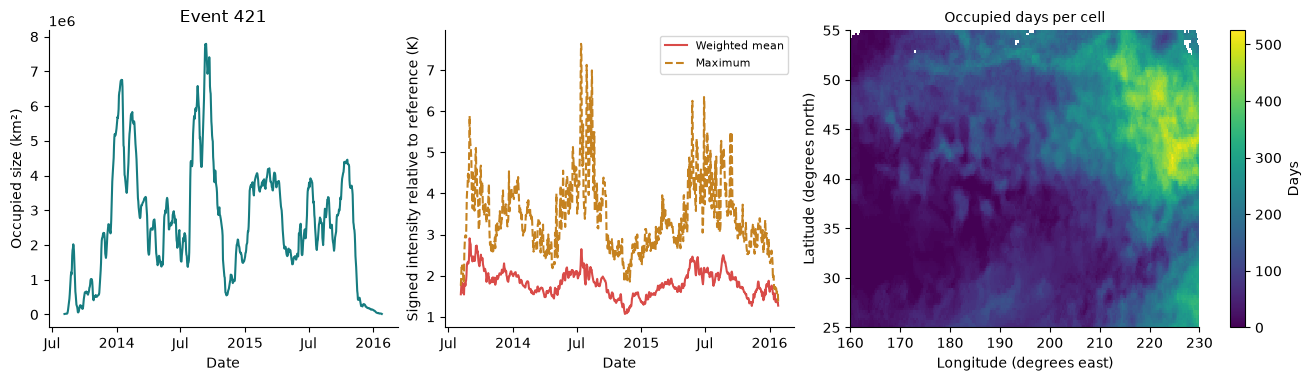

In [6]:
mask = xhw.detect(
    window, variable="sst", grid=grid, definition=mhw, baseline_result=fits["MHW"]
)
mask.check_invariants()
catalog = xhw.build_catalog(mask, analysis_mode="retrospective")
catalog.check_against(mask)
metrics["window_MHW"] = temporal_summary(mask, catalog)
series_figure(
    window,
    mask,
    variable="sst",
    selection={"lat": 79, "lon": 220},
    period=("2014-06-01", "2015-03-01"),
    output_dir=output_dir,
)
objects = xhw.build_objects(mask, recipe=SPATIAL, analysis_mode="retrospective")
objects.check_invariants()
objects.check_against(mask)
sequence_figure(objects, ["2014-01-15", "2014-09-15", "2015-01-15"], output_dir)
graph = xhw.build_lineage(objects, field=mask.intensity(), weighted=True)
graph.check_invariants()
graph.check_against(objects)
metrics["lineage_catalog_export"] = lineage_catalog_status(graph, mask)
event = largest_event(graph)
genealogy_figure(graph, event, output_dir)
metrics_figure(graph, objects, event, output_dir)
metrics["spatial"] = spatial_summary(objects, graph)
metrics["largest_size_time_event"] = int(event)

## Record the run; the review state stays explicit

The report holds versions, exact specs, source checksum and review state.

In [7]:
report = write_report(
    output_dir,
    "oisst_npacific",
    metrics,
    grid=grid,
    baseline=baseline,
    definition=mhw,
    recipe=SPATIAL,
    graph=graph,
    review="executed; summaries pending scientific review",
    extra={
        "selection": "North Pacific: lat 25 to 55; lon 160 to 230 (0-360); 1991–2025",
        "object_window": list(WINDOW),
        "min_area": "absolute 10 000 km2 (the default 5% removes 99% of patches)",
        "ocean_cells": ocean_cells,
        "temporal_block_rows": BLOCK_ROWS,
        "temporal_time_selection": "complete 1991–2025 series per cell; spatial stages global",
    },
)

{
  "MHW": {
    "exceedance_cell_days": 56418997,
    "event_cell_days": 47086786,
    "joined_cell_days": 557179,
    "valid_cell_days": 428775360,
    "filled_cell_days": 0
  },
  "MCS": {
    "exceedance_cell_days": 36746366,
    "event_cell_days": 26880267,
    "joined_cell_days": 386975,
    "valid_cell_days": 428775360,
    "filled_cell_days": 0
  },
  "window_MHW": {
    "events": 590598,
    "exceedance_cell_days": 12455255,
    "event_cell_days": 10127131,
    "joined_cell_days": 158186,
    "valid_cell_days": 85761780,
    "filled_cell_days": 0,
    "max_duration_days": 275
  },
  "lineage_catalog_export": {
    "status": "not exportable as qualified EventCatalog",
    "short_components": 308,
    "reason": "qualified events shorter than min_duration_days"
  },
  "spatial": {
    "patches": 39388,
    "tracks": 1514,
    "branches": 8548,
    "spacetime_events": 1822,
    "splits": 1663,
    "merges": 1655,
    "max_size": 7162848364328.62,
    "size_units": "m2",
    "max_s

## Interpretation and provenance

Inspect the executed report. Keep domain, grid, reference, tail, missing policy, persistence, connectivity and overlap denominator attached to these numbers. Genealogy is not attribution. These are reproduced numbers pending scientific review; figures are produced by xarray/Matplotlib, not a native xHW graphics API.

In [8]:
{
    "review_status": report["review_status"],
    "versions": report["versions"],
    "source_checksum": report["source"]["fields"]["checksum"],
}

{'review_status': 'executed; summaries pending scientific review',
 'versions': {'xhw': '0.1.0',
  'numpy': '2.5.4',
  'xarray': '2026.7.0',
  'scipy': '1.16.3',
  'matplotlib': '3.11.2',
  'h5netcdf': '1.8.1',
  'nbformat': '5.11.1',
  'nbclient': '0.11.0'},
 'source_checksum': 'sha256:e89d0a120dc156b70844e5118e2c2df435b3b0641ef806d69e0cf15d79ed0546'}

## Explore already computed products

Install `examples/requirements-interactive.txt` in this kernel, then use date, layer,
event/branch and cell controls. Map zoom and pan use the mouse. Date and cell sliders
update on release. Disabled event controls mean that the selected case has temporal
products only. TX+TN temperature panels show the first daily component.

The controls do not fit baselines or rerun detection/tracking. Static figures and tables
above remain readable on GitHub; these controls need a live Jupyter kernel.


In [9]:
from exploration import explorer

cases = {"MHW": (mask, objects, graph)}
explorer(cases)
